<a href="https://colab.research.google.com/github/elonsobrevilla06-byte/Jeepney_ObjectDetection_OCR/blob/main/Jeepney_ObjectDetection_OCR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
zip_name = "/content/drive/MyDrive/jeepney-ocr/Jeep.v1i.yolov8.zip"

In [ ]:

BASE = "/content/drive/MyDrive/jeepney-ocr"
zip_name = "/content/drive/MyDrive/jeepney-ocr/Jeep.v1i.yolov8.zip"

# Check Drive

In [ ]:
import os

if os.path.exists(zip_name):
    print("ZIP file found!")
else:
    print("ZIP file NOT found!")

ZIP file found!


# Training

In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


In [ ]:
!pip install -q ultralytics easyocr rapidfuzz

In [ ]:
!unzip -q -o "{zip_name}" -d /content/jeep_dataset
!ls /content/jeep_dataset

data.yaml  README.dataset.txt  README.roboflow.txt  test  train  valid


In [ ]:
import yaml

yaml_path = "/content/jeep_dataset/data.yaml"
with open(yaml_path) as f:
    cfg = yaml.safe_load(f)

cfg["path"] = "/content/jeep_dataset"
cfg["train"] = "train/images"
cfg["val"] = "valid/images"
cfg["test"] = "test/images"

with open(yaml_path, "w") as f:
    yaml.dump(cfg, f)

print(cfg["names"], cfg["nc"])

['Jeep'] 1


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")
model.train(
    data=yaml_path,
    epochs=100,
    imgsz=640,
    batch=16,
    patience=25,
    cache=True,
    close_mosaic=10,
    hsv_h=0.015, hsv_s=0.6, hsv_v=0.4,
    degrees=5, scale=0.5,
    project=f"{BASE}/runs",
    name="jeep_v2",
    seed=0,
)

BEST = str(model.trainer.best)
print("best.pt is at:", BEST)

In [ ]:
from ultralytics import YOLO
BEST = f"{BASE}/runs/jeep_v2/weights/best.pt"
model = YOLO(BEST)

# Test Detection

In [ ]:
import glob
from IPython.display import Image, display

results = model.predict(
    source="/content/jeep_dataset/test/images",
    conf=0.4, save=True, project="/content/preds", name="test"
)

for p in glob.glob("/content/preds/test/*.jpg")[:5]:
    display(Image(p))

In [ ]:
import json, re, collections
from rapidfuzz import fuzz, process

ROUTES_JSON = f"{BASE}/route_test.json"
routes = json.load(open(ROUTES_JSON))

GENERIC = {"city","road","intersection","street","avenue","ave","highway","station","near",
           "via","mjeep","unnamed","un","named","terminal","the","and","to","of","st",
           "subd","subdivision","elementary","school","hospital"}

def clean_phrase(s):
    s = re.sub(r"[^a-z0-9 ]", " ", s.lower())
    return " ".join(w for w in s.split() if w not in GENERIC)

def phrases(text):
    out = set()
    for part in re.split(r"[,/()\-:]|\bvia\b|\band\b|\bto\b", text, flags=re.I):
        p = clean_phrase(part)
        if len(p) >= 4 and not p.isdigit():
            out.add(p)
    return out

kw_routes = collections.defaultdict(dict)
code2routes = collections.defaultdict(list)
route_meta = {}

def add(rid, text, w):
    for p in phrases(text):
        kw_routes[p][rid] = max(kw_routes[p].get(rid, 0), w)

for r in routes:
    rid = r["id"]
    code, _, title = r["name"].partition(":")
    if not title:
        code, title = "", code
    code, title = code.strip(), title.strip()
    if code:
        code2routes[code].append(rid)
    route_meta[rid] = {k: r[k] for k in ("name", "fare", "runs_between", "schedule", "url")}
    add(rid, title, 3.0)
    add(rid, r["runs_between"], 2.0)
    for t in r["trips"]:
        for s in t["stops"]:
            add(rid, s, 1.0)

KEYWORDS = [k for k in kw_routes if len(k) >= 5]
print(len(routes), "routes,", len(KEYWORDS), "keywords")

In [ ]:
def match_route(ocr_text, top_k=3, fuzzy_cutoff=85):
    txt = " ".join(re.sub(r"[^a-z0-9 ]", " ", ocr_text.lower()).split())
    scores, why = collections.Counter(), collections.defaultdict(list)

    for num in set(re.findall(r"\b\d{2,4}\b", txt)):
        for rid in code2routes.get(num, []):
            scores[rid] += 4.0
            why[rid].append(f"code {num}")

    if txt:
        for kw, s, _ in process.extract(txt, KEYWORDS, scorer=fuzz.partial_ratio,
                                        score_cutoff=fuzzy_cutoff, limit=None):
            n = len(kw_routes[kw])
            for rid, w in kw_routes[kw].items():
                scores[rid] += (s / 100) * w / n
                why[rid].append(f"{kw} ({s:.0f})")

    return [{"route_id": rid, "score": round(sc, 2), "matched": why[rid][:6], **route_meta[rid]}
            for rid, sc in scores.most_common(top_k)]

# OCR

In [ ]:
import cv2, easyocr
from google.colab.patches import cv2_imshow

detector = YOLO(BEST)
reader = easyocr.Reader(["en", "tl"], gpu=True)
MIN_SCORE = 1.0

def ocr_variants(img):
    if max(img.shape[:2]) < 800:
        img = cv2.resize(img, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    eq = cv2.createCLAHE(2.0, (8, 8)).apply(gray)
    return [img, eq, 255 - eq]

def ocr_crop(crop, min_conf=0.3):
    texts = []
    for v in ocr_variants(crop):
        texts += [t for _, t, c in reader.readtext(v) if c >= min_conf]
    return texts

def read_jeeps(image_path, conf=0.4, pad=0.05, show=True):
    img = cv2.imread(image_path)
    H, W = img.shape[:2]
    results = []
    for box in detector.predict(img, conf=conf, verbose=False)[0].boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        px, py = int((x2 - x1) * pad), int((y2 - y1) * pad)
        crop = img[max(0, y1 - py):min(H, y2 + py), max(0, x1 - px):min(W, x2 + px)]

        texts = ocr_crop(crop)
        matches = match_route(" ".join(texts))
        best = matches[0] if matches and matches[0]["score"] >= MIN_SCORE else None

        results.append({"bbox": (x1, y1, x2, y2), "ocr_text": texts,
                        "route": best, "candidates": matches})

        label = best["name"] if best else "unknown route"
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, label, (x1, max(25, y1 - 10)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (0, 255, 0), 2)
    if show:
        cv2_imshow(img)
    return results

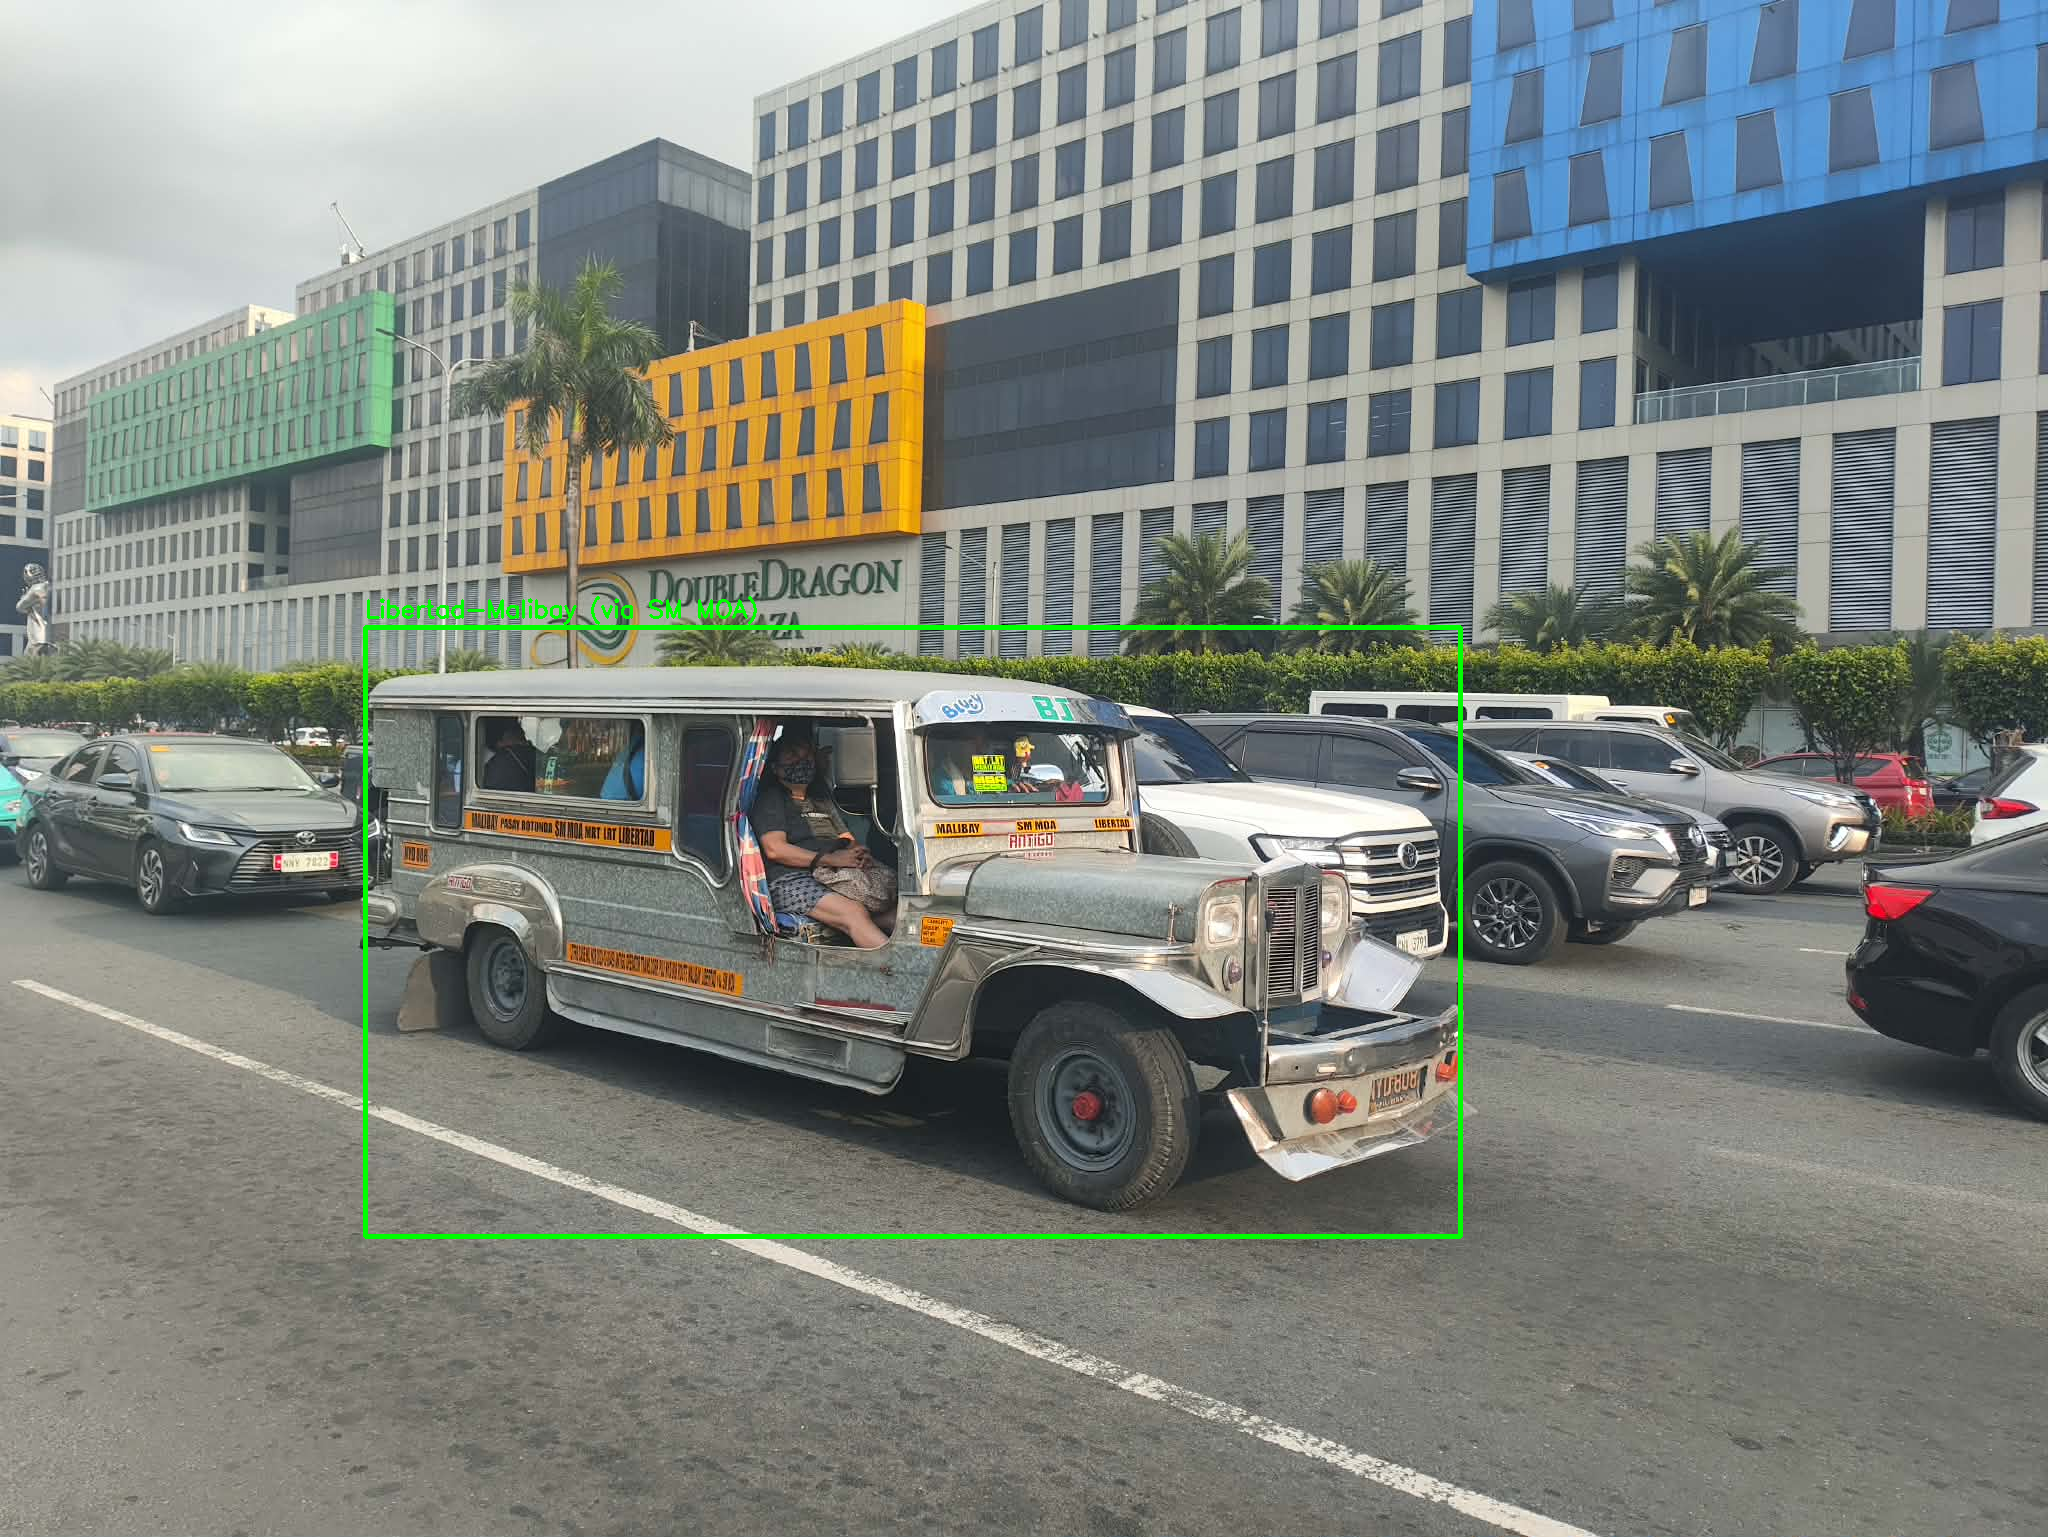

Found 1 jeepney(s)

--- Jeep 1 ---
OCR TEXT: ['ZA', 'MALBIY', 'SM Mon', 'Viberinn', 'ZA', 'MALBAY', 'ZA', 'Adigd']
ROUTE: Libertad-Malibay (via SM MOA)
    2.57  Libertad-Malibay (via SM MOA)  <- ['malibay (86)']


In [ ]:
IMG = f"{BASE}/malinis_na_pic.jpg"
assert os.path.exists(IMG), "Image not found"

jeeps = read_jeeps(IMG, conf=0.4)
print(f"Found {len(jeeps)} jeepney(s)\n")
for i, j in enumerate(jeeps, 1):
    print(f"--- Jeep {i} ---")
    print("OCR TEXT:", j["ocr_text"])
    print("ROUTE:", j["route"]["name"] if j["route"] else "unknown")
    for c in j["candidates"]:
        print(f"   {c['score']:>5}  {c['name']}  <- {c['matched'][:3]}")

# Save Model

In [ ]:
import shutil

OUT = f"{BASE}/android_export"
os.makedirs(OUT, exist_ok=True)

# 1) detector -> TFLite
path = YOLO(BEST).export(format="tflite", imgsz=640)
export_dir = path if os.path.isdir(path) else os.path.dirname(path)
for f in os.listdir(export_dir):
    if f.endswith(".tflite"):
        shutil.copy(os.path.join(export_dir, f), OUT)
shutil.copy(BEST, OUT)

# 2) route index for the Kotlin matcher
index = {
    "keywords": {k: v for k, v in kw_routes.items() if len(k) >= 5},
    "code2routes": dict(code2routes),
    "route_meta": route_meta,
    "min_score": MIN_SCORE,
    "fuzzy_cutoff": 85,
}
with open(f"{OUT}/route_index.json", "w", encoding="utf-8") as f:
    json.dump(index, f, ensure_ascii=False)

print(os.listdir(OUT))